In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

df = pd.read_excel('D:\internship project\BlinkiIT_Grocery_Sales_Analysis\Data\Raw\BlinkIT Grocery Data.xlsx')

In [3]:
print("DataFrame Shape:", df.shape)
print(df.info())

DataFrame Shape: (8523, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
None


In [4]:
print(df.columns.tolist())

['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']


In [11]:
product_types_count = df['Item Type'].value_counts()
print ("Number of unique items", df['Item Type'].nunique())
display(product_types_count.to_frame(name="Record_Count"))
display(
    product_types_count
    .rename_axis("Product Type")
    .reset_index(name="Record Count")
)


Number of unique items 16


,Record_Count
Item Type,
Fruits and Vegetables,1232
Snack Foods,1200
Household,910
Frozen Foods,856
Dairy,682
Canned,649
Baking Goods,648
Health and Hygiene,520
Soft Drinks,445


,Product Type,Record Count
0,Fruits and Vegetables,1232
1,Snack Foods,1200
2,Household,910
3,Frozen Foods,856
4,Dairy,682
5,Canned,649
6,Baking Goods,648
7,Health and Hygiene,520
8,Soft Drinks,445
9,Meat,425


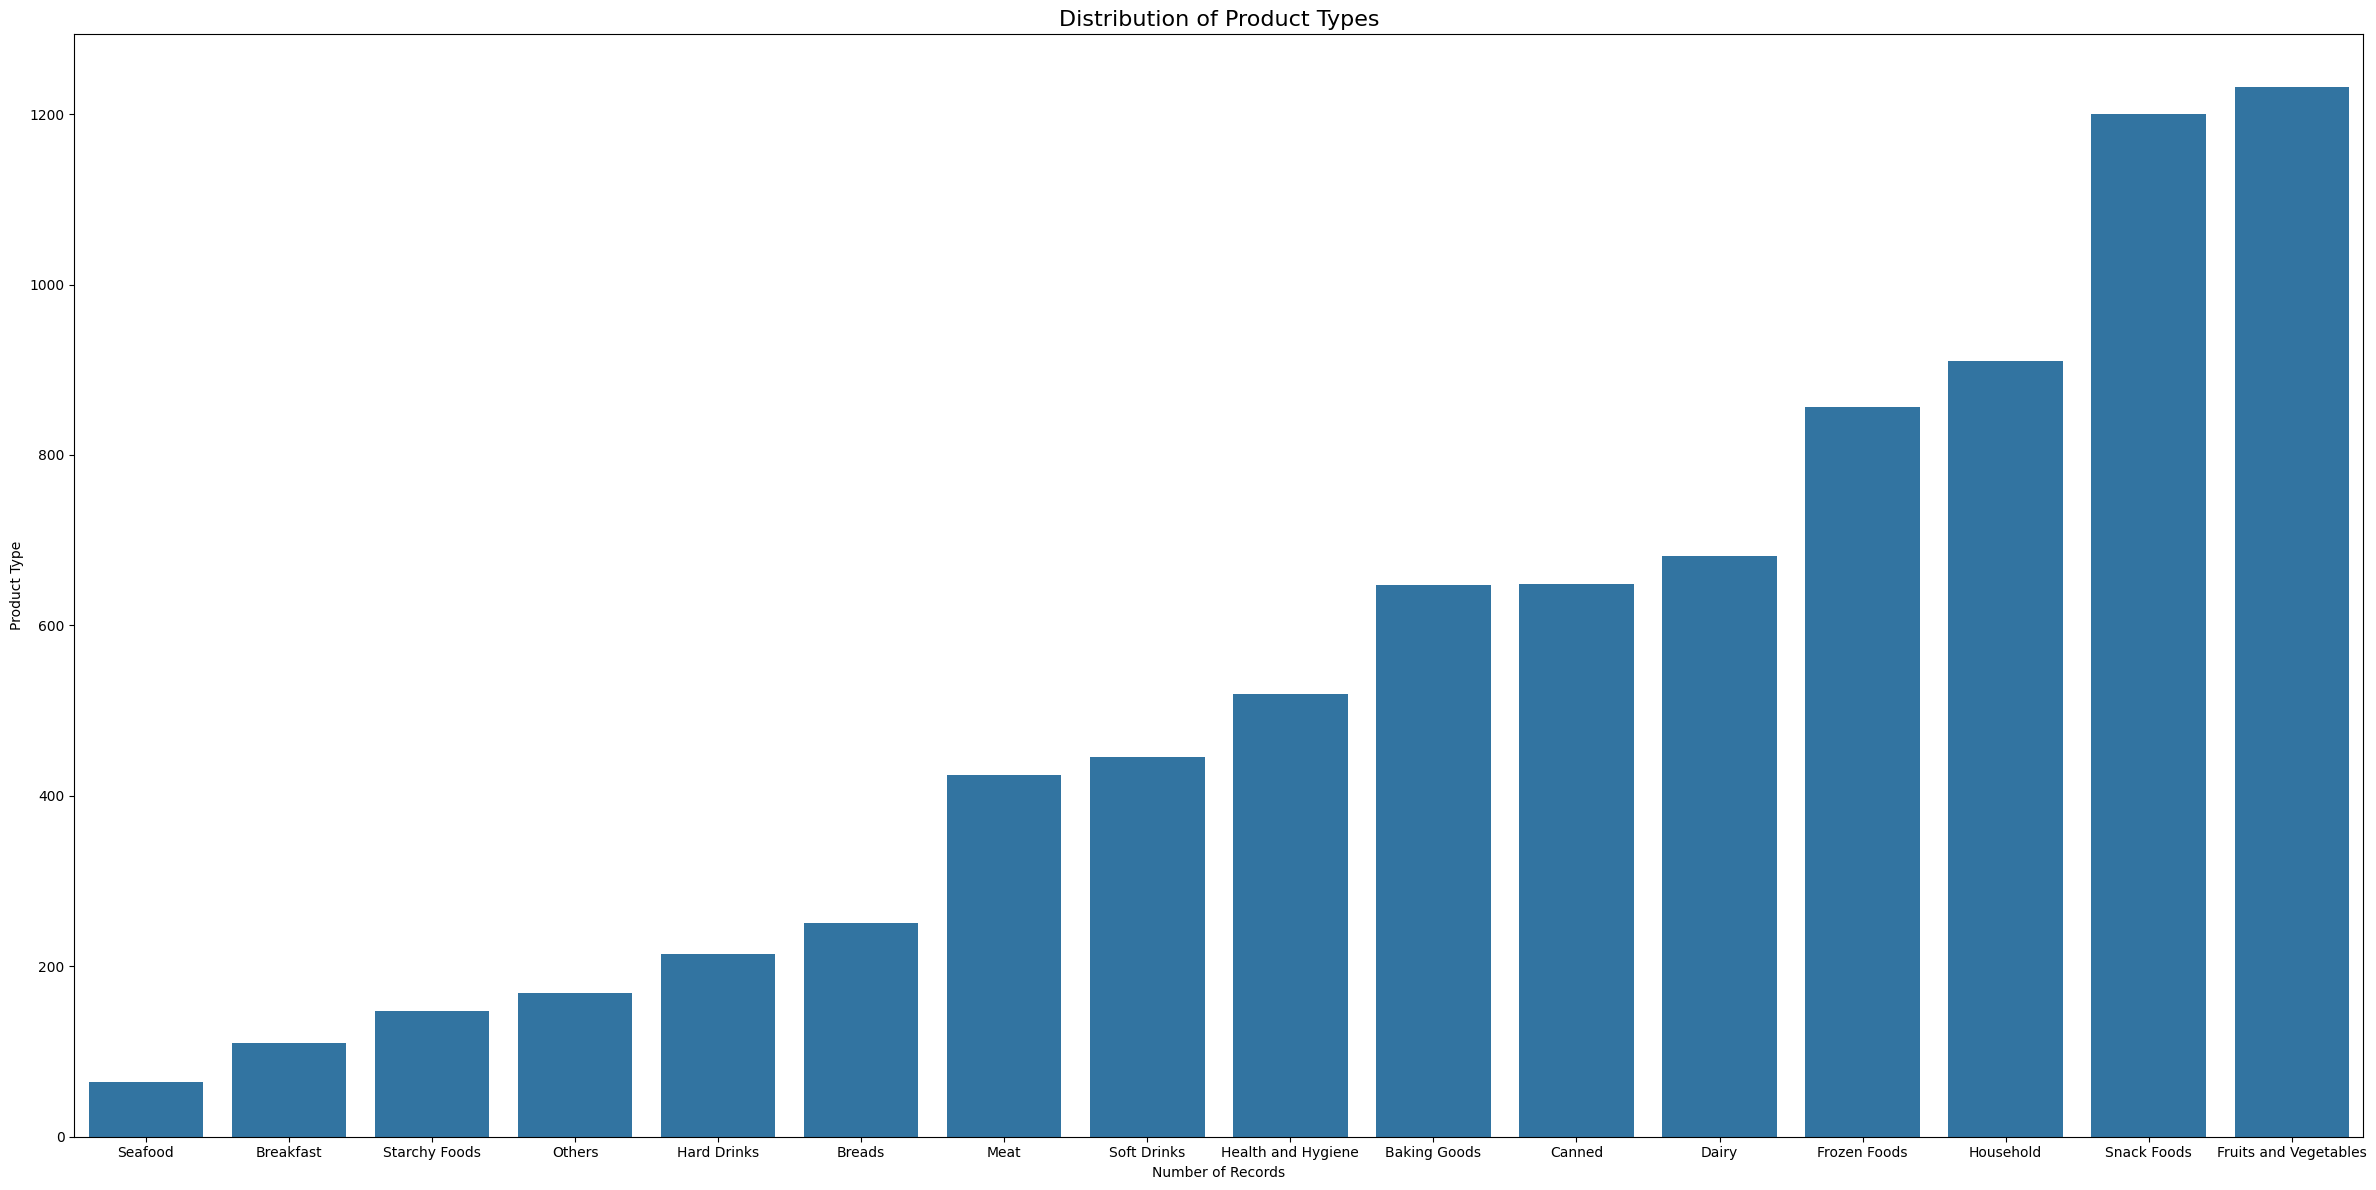

In [21]:
products_type_count = df['Item Type'].value_counts().sort_values()
plt.figure(figsize=(24,12))
sns.barplot(x=products_type_count.index, y=products_type_count.values)
plt.title('Distribution of Product Types', fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Product Type")
plt.tight_layout()

figure_path = Path('D:\internship project\BlinkiIT_Grocery_Sales_Analysis\Reports\Figures\product_types_distribution.png')
plt.savefig(figure_path, dpi=300)


Task 1.1: Analyze Product Types

The dataset contains 16 product categories. Fruits and Vegetables (1,232 records) and Snack Foods (1,200 records) have the highest representation. Seafood (64 records) and Breakfast (110 records) have the fewest records. This provides an initial understanding of product-category distribution in the dataset.

In [22]:

## task 1.2 

outlet_summary = df.groupby(
    ["Outlet Type", "Outlet Location Type", "Outlet Size"],
    dropna=False
).size().reset_index(name="Record Count")

display(outlet_summary)


,Outlet Type,Outlet Location Type,Outlet Size,Record Count
0,Grocery Store,Tier 1,Small,528
1,Grocery Store,Tier 3,High,233
2,Grocery Store,Tier 3,Medium,265
3,Grocery Store,Tier 3,Small,57
4,Supermarket Type1,Tier 1,Medium,930
5,Supermarket Type1,Tier 1,Small,930
6,Supermarket Type1,Tier 2,High,588
7,Supermarket Type1,Tier 2,Medium,573
8,Supermarket Type1,Tier 2,Small,1624
9,Supermarket Type1,Tier 3,High,932


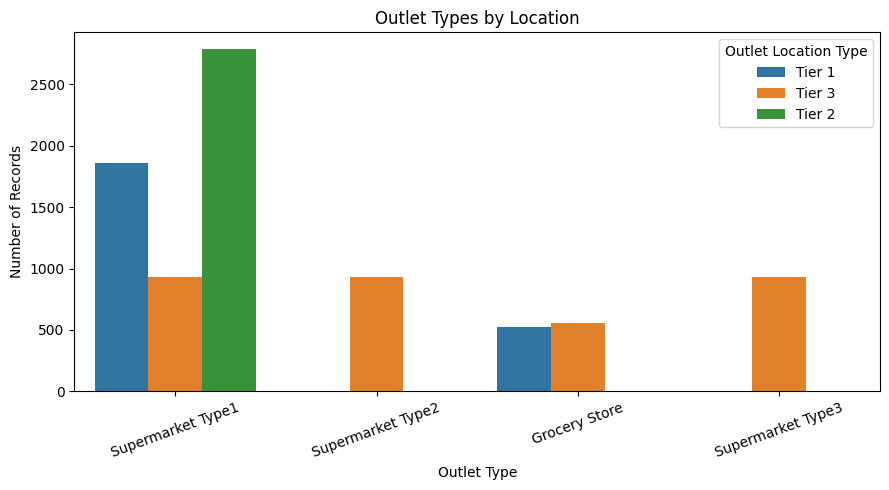

In [23]:

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Outlet Type", hue="Outlet Location Type")

plt.title("Outlet Types by Location")
plt.xlabel("Outlet Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("../reports/figures/task1_outlets.png", dpi=300, bbox_inches="tight")
plt.show()


Task 1.2: Analyze Outlet Characteristics

The dataset contains different outlet types, location tiers, and outlet sizes. Supermarket Type 1 appears across multiple location tiers and sizes, while the other outlet types have more limited combinations. These characteristics provide useful dimensions for comparing outlet performance.

In [24]:
# Task 1.3 

total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
total_records = len(df)

print(f"Total Sales: {total_sales:,.2f}")
print(f"Average Sales per Record: {average_sales:,.2f}")
print(f"Total Records: {total_records:,}")

Total Sales: 1,201,681.49
Average Sales per Record: 140.99
Total Records: 8,523


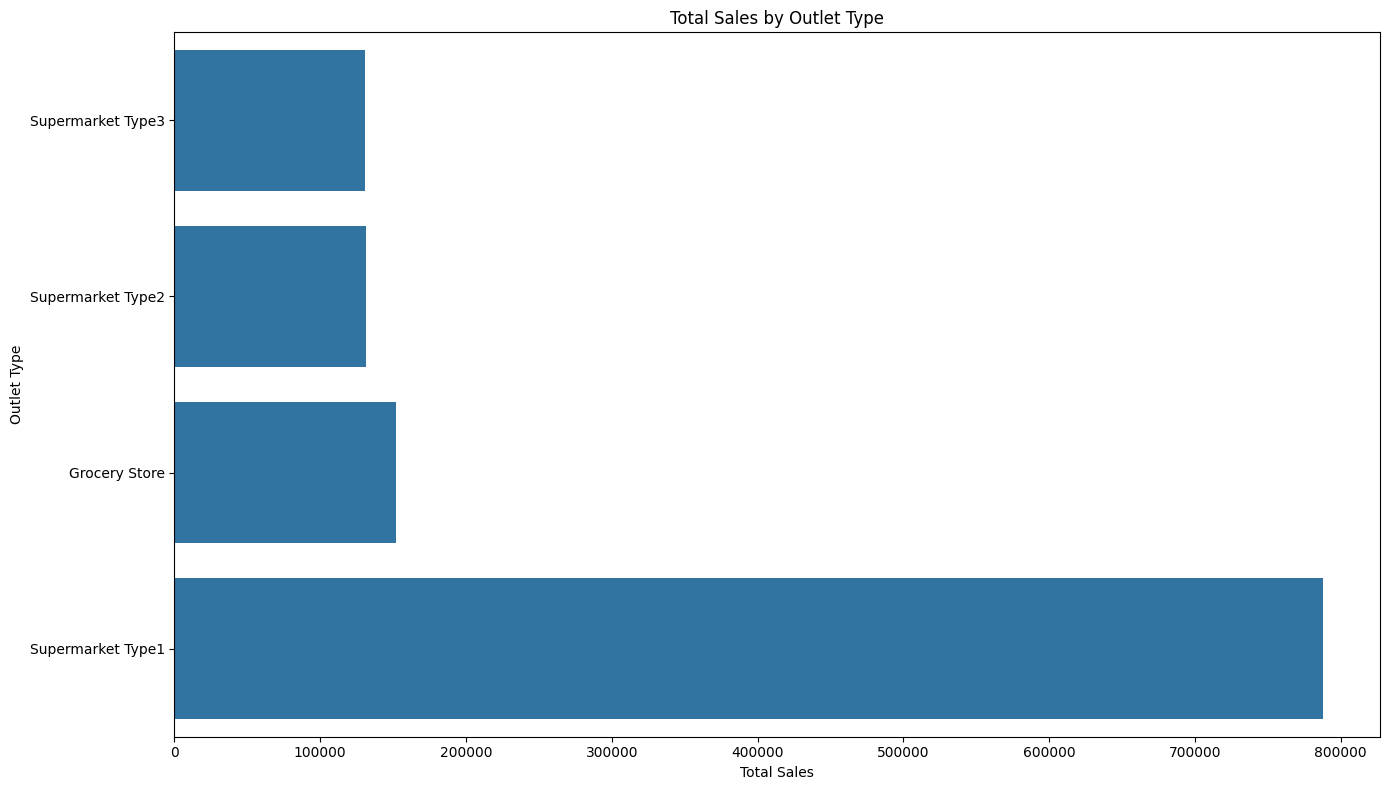

In [25]:
sales_by_outlet = df.groupby("Outlet Type")["Sales"].sum().sort_values()

plt.figure(figsize=(14, 8))
sns.barplot(x=sales_by_outlet.values, y=sales_by_outlet.index)

plt.title("Total Sales by Outlet Type")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Type")
plt.tight_layout()

plt.savefig("../reports/figures/task1_sales.png", dpi=300, bbox_inches="tight")
plt.show()

Task 1.3: Calculate Key Sales Metrics

The dataset contains 8,523 records, with total sales of 1,201,681.49 and average sales per record of 140.99. These metrics provide a baseline for evaluating product and outlet performance throughout the analysis.

In [26]:
# Task 1.4

print("Average Customer Rating:", df["Rating"].mean())
print("Highest Customer Rating:", df["Rating"].max())
print("Lowest Customer Rating:", df["Rating"].min())

print("\nTop 5 Item Types by Total Sales:")
print(
    df.groupby("Item Type")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

Average Customer Rating: 3.965857092573038
Highest Customer Rating: 5.0
Lowest Customer Rating: 1.0

Top 5 Item Types by Total Sales:
Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Name: Sales, dtype: float64


Task 1.4: Analyze Customer Ratings and Top-Selling Categories

The average customer rating is approximately 3.97, with ratings ranging from 1 to 5. Fruits and Vegetables generated the highest total sales (178,124.08), followed by Snack Foods (175,433.92), Household (135,976.53), Frozen Foods (118,558.88), and Dairy (101,276.46). These categories are the leading contributors to sales in the dataset.

In [30]:
# Task 2.1 

df.isnull().sum()




Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [31]:
df.isnull().sum().sum()


np.int64(1463)

In [32]:
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].median())

In [33]:
df['Item Weight'].isnull().sum()

np.int64(0)

Task 2.1: Identify Missing Values

The initial missing-value check identified 1,463 missing values in the Item Weight column. All other columns had zero missing values. Item Weight was therefore the primary column requiring missing-value treatment.

In [34]:
# Task 2.2 

df.duplicated().sum()

np.int64(0)

In [35]:
df[df.duplicated()]

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


Task 2.2: Check for Duplicate Records

The dataset was checked for duplicate records across its columns. The displayed duplicate-check result contained no duplicate rows, indicating that duplicate removal was not required.

In [36]:
# Task 2.3 

df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,8523.00000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.81342,140.992783,3.965857
std,3.189396,0.051598,4.22724,62.275067,0.605651
min,2011.000000,0.000000,4.55500,31.290000,1.000000
25%,2014.000000,0.026989,9.31000,93.826500,4.000000
50%,2016.000000,0.053931,12.60000,143.012800,4.000000
75%,2018.000000,0.094585,16.00000,185.643700,4.200000
max,2022.000000,0.328391,21.35000,266.888400,5.000000


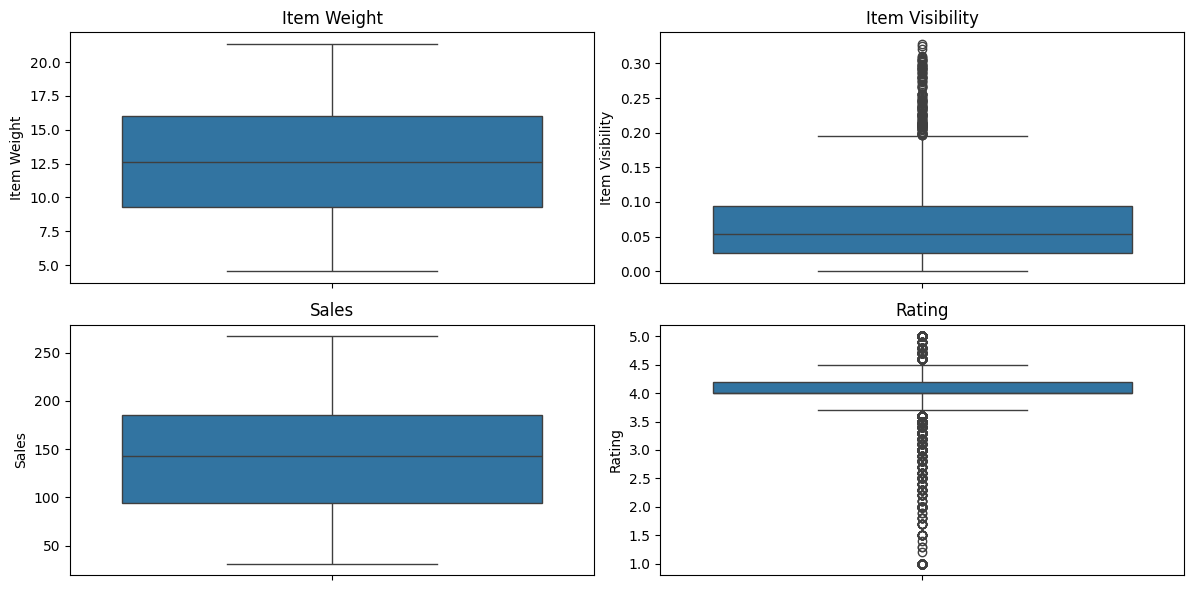

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['Item Weight', 'Item Visibility', 'Sales', 'Rating']

plt.figure(figsize=(12, 6))

for i, col in enumerate(cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [38]:
df[['Item Visibility', 'Rating']].agg(['min', 'max'])

,Item Visibility,Rating
min,0.000000,1.0
max,0.328391,5.0


Task 2.3: Examine Descriptive Statistics and Potential Outliers

Descriptive statistics were used to examine Outlet Establishment Year, Item Visibility, Item Weight, Sales, and Rating. Sales ranged from 31.29 to 266.89, while Item Visibility ranged from 0 to approximately 0.3284. Customer ratings ranged from 1 to 5. These statistics, together with the visualizations, helped assess variable distributions and identify potential outliers for further consideration.

In [39]:
# Task 2.4 

df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [40]:
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

In [41]:
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Task 2.4: Standardize Item Fat Content

The Item Fat Content column contained inconsistent labels, including Low Fat, LF, low fat, Regular, and reg. These labels represent duplicate categories caused by inconsistent formatting. Standardizing them into the two categories, Low Fat and Regular, improves data consistency and supports more reliable category-based analysis.

In [42]:
# Task 3.1 

sales_by_type = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_type)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


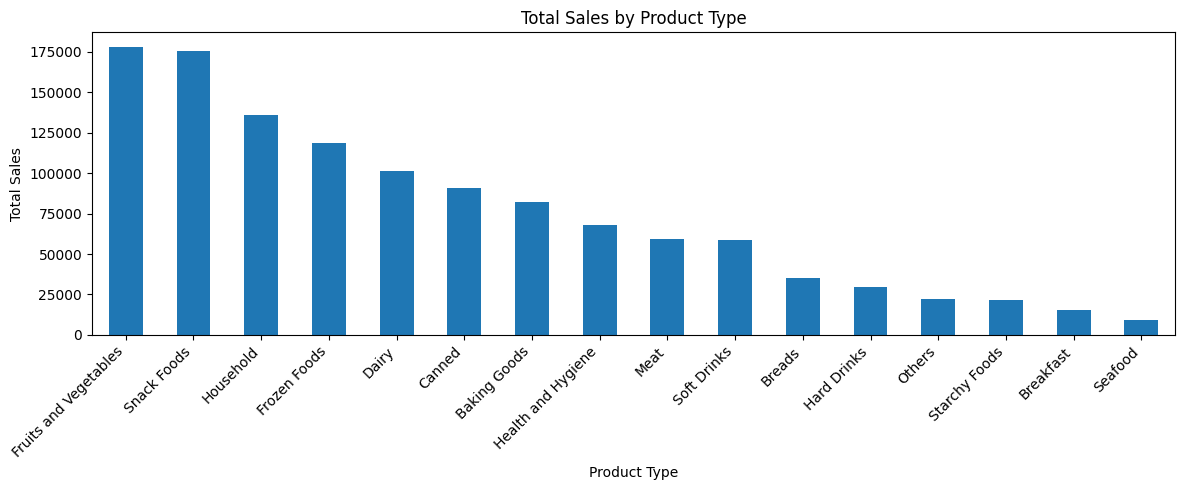

In [47]:
sales_by_type.plot(
    kind='bar',
    figsize=(12, 5),
    title='Total Sales by Product Type'
)

plt.xlabel('Product Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig("../reports/figures/task3.1_sales_by_type.png", dpi=300, bbox_inches="tight")
plt.show()

Task 3.1: Identify Product Types Selling More

Fruits and Vegetables and Snack Foods were the highest-selling product categories by total sales, generating 178,124.08 and 175,433.92, respectively. Household, Frozen Foods, and Dairy were the next three leading categories. These results highlight the product categories contributing most to overall sales.

In [48]:
# Task 3.2 

sales_by_outlet = df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False)

print(sales_by_outlet)

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


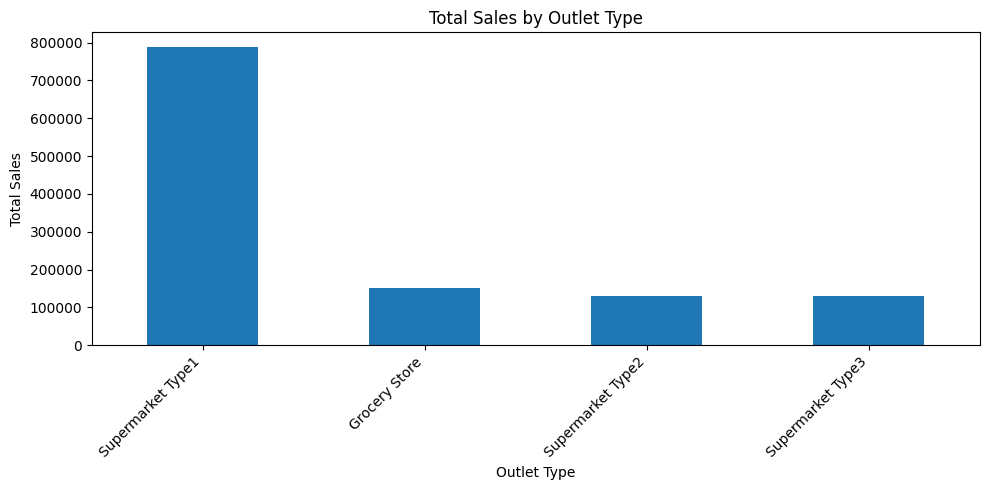

In [49]:
sales_by_outlet.plot(
    kind='bar',
    figsize=(10, 5),
    title='Total Sales by Outlet Type'
)

plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig("../reports/figures/task3.2_sales_by_outlet_type.png", dpi=300, bbox_inches="tight")
plt.show()

Task 3.2: Identify Better-Performing Outlet Types

Outlet types were compared to understand their sales performance. Supermarket Type 1 generated the highest total sales, while Supermarket Type 3 generated the lowest total sales among the outlet types. This comparison highlights differences in overall sales contribution across outlet formats.

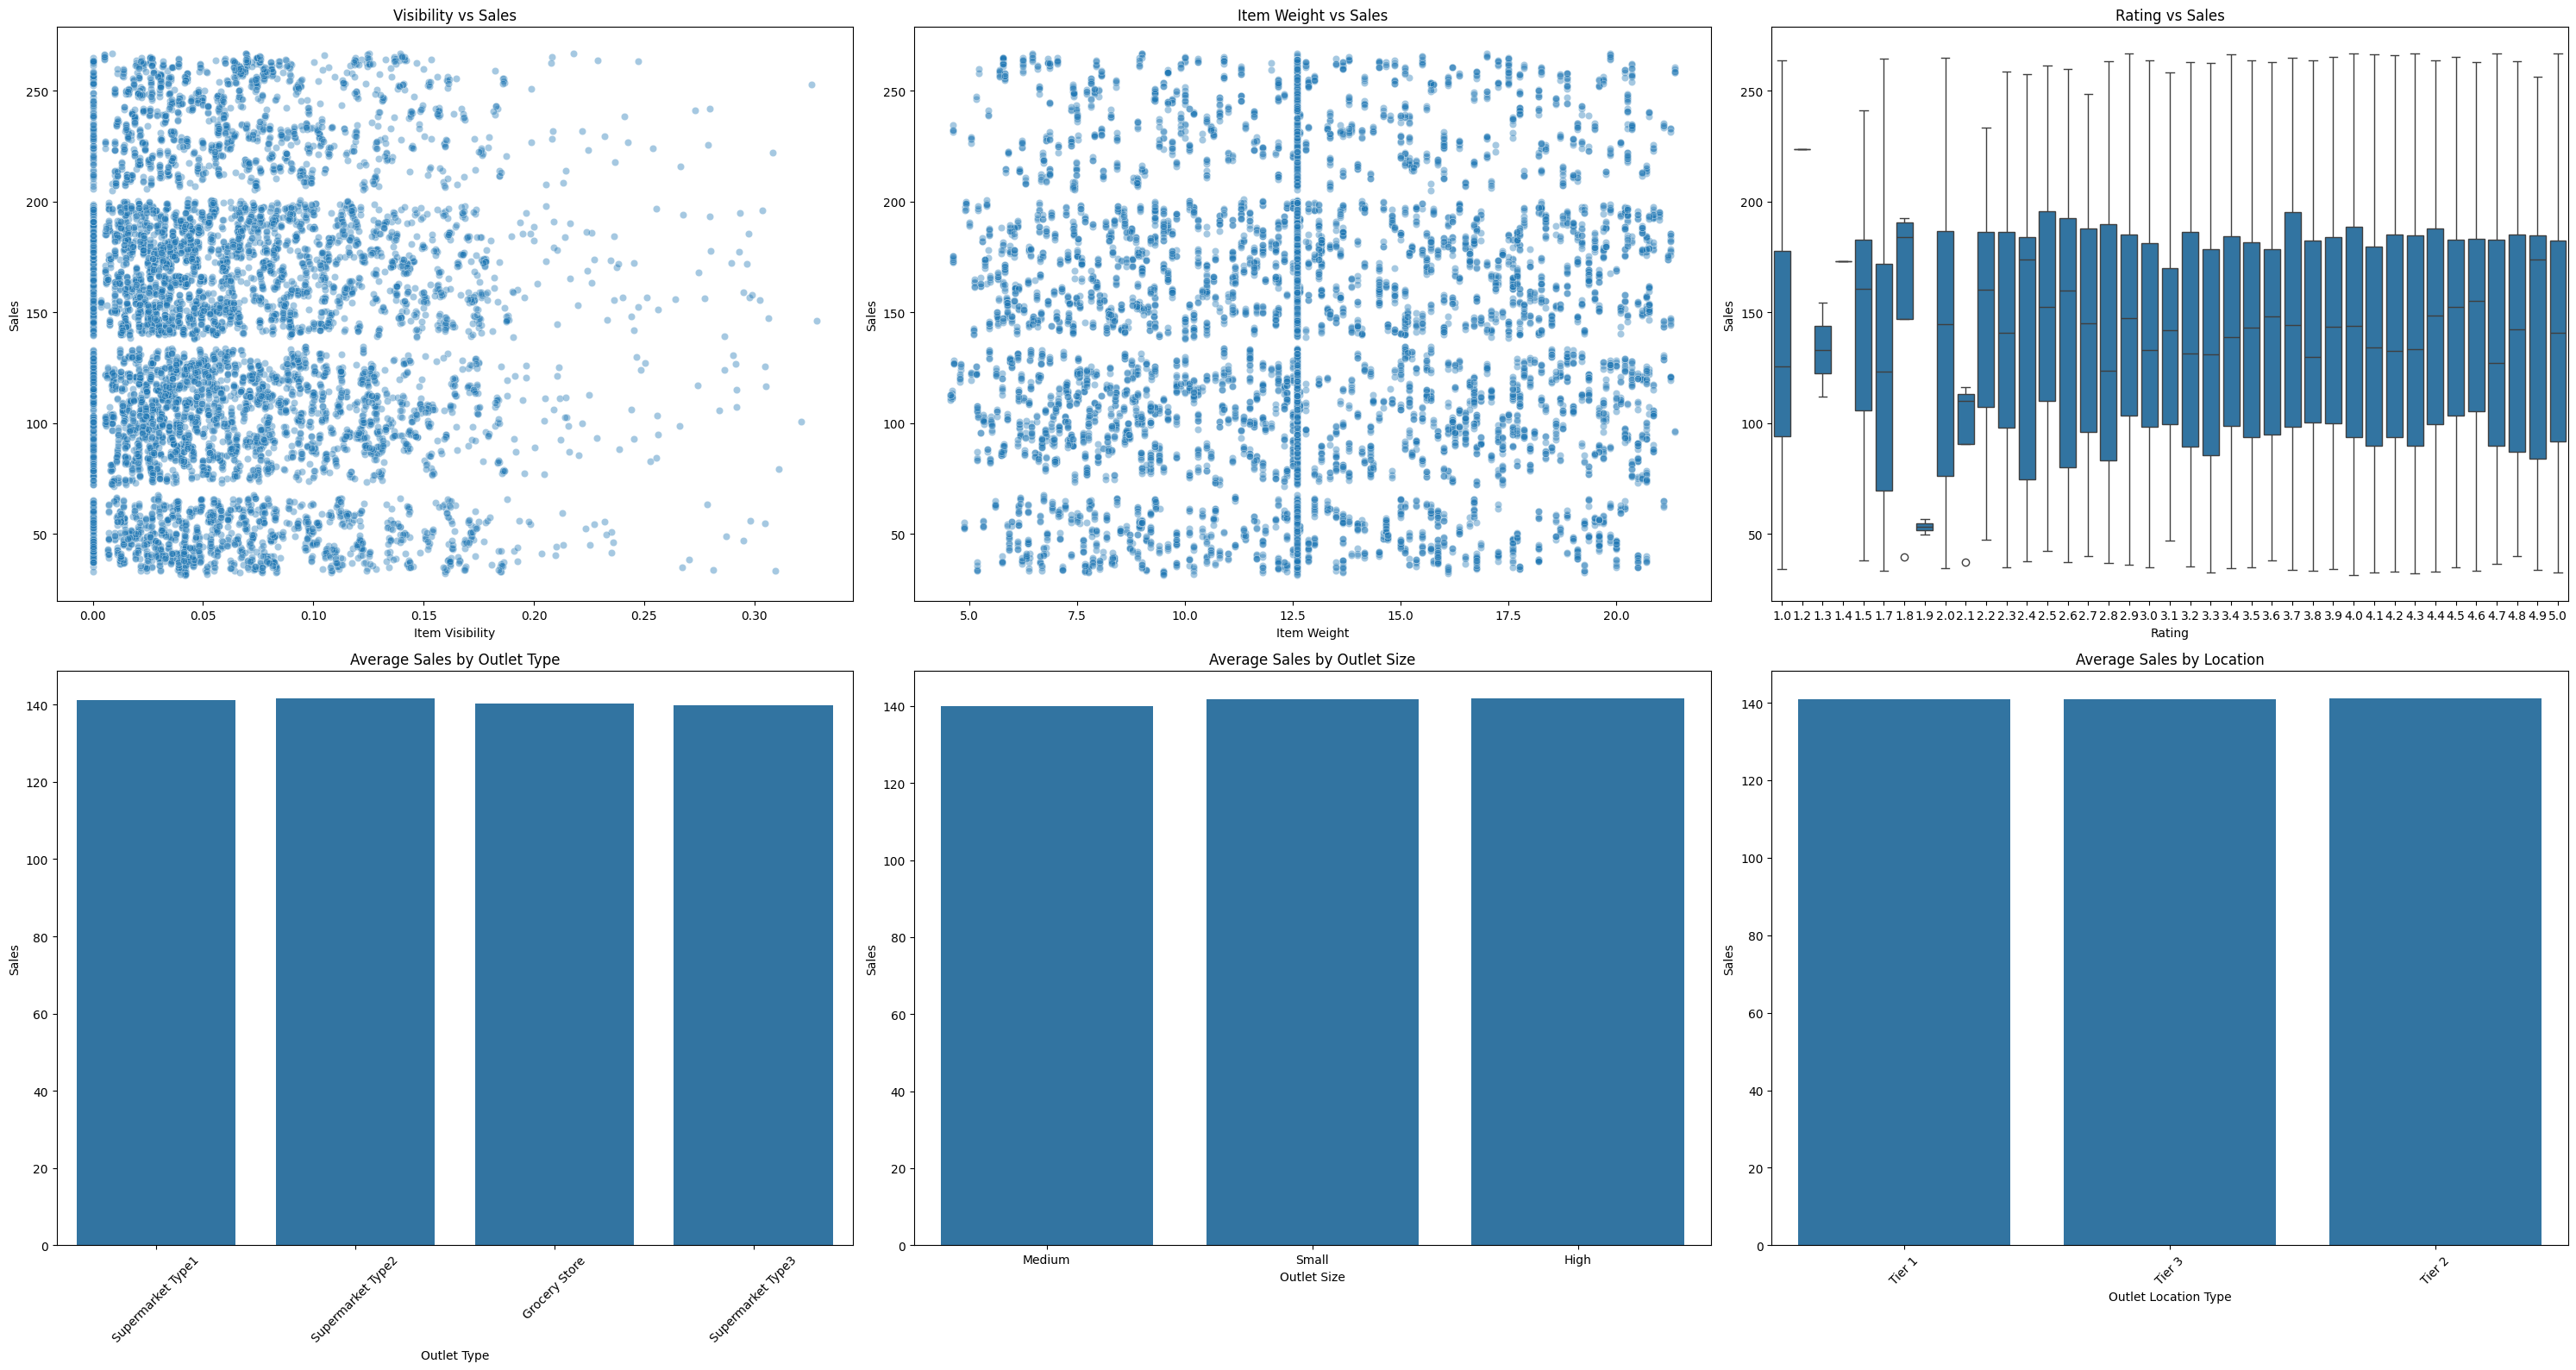

In [55]:
# Task 3.3

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(30, 16))

# Numerical factors
sns.scatterplot(data=df, x='Item Visibility', y='Sales', alpha=0.4, ax=axes[0, 0])
axes[0, 0].set_title('Visibility vs Sales')

sns.scatterplot(data=df, x='Item Weight', y='Sales', alpha=0.4, ax=axes[0, 1])
axes[0, 1].set_title('Item Weight vs Sales')

sns.boxplot(data=df, x='Rating', y='Sales', ax=axes[0, 2])
axes[0, 2].set_title('Rating vs Sales')

# Outlet characteristics
sns.barplot(data=df, x='Outlet Type', y='Sales', estimator='mean', errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title('Average Sales by Outlet Type')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.barplot(data=df, x='Outlet Size', y='Sales', estimator='mean', errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title('Average Sales by Outlet Size')

sns.barplot(data=df, x='Outlet Location Type', y='Sales', estimator='mean', errorbar=None, ax=axes[1, 2])
axes[1, 2].set_title('Average Sales by Location')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("../reports/figures/task3.3_sales_factors.png", dpi=300, bbox_inches="tight")
plt.show()

In [56]:
df[['Item Visibility', 'Item Weight', 'Rating', 'Sales']].corr()['Sales']

Item Visibility   -0.001315
Item Weight        0.024951
Rating             0.011329
Sales              1.000000
Name: Sales, dtype: float64

In [57]:
print(df.groupby('Outlet Type')['Sales'].mean().sort_values(ascending=False))
print(df.groupby('Outlet Size')['Sales'].mean().sort_values(ascending=False))
print(df.groupby('Outlet Location Type')['Sales'].mean().sort_values(ascending=False))

Outlet Type
Supermarket Type2    141.678638
Supermarket Type1    141.213895
Grocery Store        140.294690
Supermarket Type3    139.801791
Name: Sales, dtype: float64
Outlet Size
High      142.037414
Small     141.699322
Medium    139.877647
Name: Sales, dtype: float64
Outlet Location Type
Tier 2    141.167198
Tier 3    140.935234
Tier 1    140.870106
Name: Sales, dtype: float64


Task 3.3: Examine Relationships Between Product and Outlet Characteristics and Sales

The correlation analysis showed very weak linear relationships between Sales and Item Visibility (-0.0013), Item Weight (0.0250), and Rating (0.0113).

Supermarket Type 2 had the highest average sales per record (141.68), followed by Supermarket Type 1 (141.21). High-sized outlets had the highest average sales by outlet size (142.04), while Tier 2 locations had the highest average sales by location tier (141.17). The differences in average sales were small, suggesting that these characteristics alone do not strongly explain sales variation.

In [58]:
# Task 3.4 

item_sales = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

print("Top 5 Performing Product Categories:")
print(item_sales.head(5))

print("\nBottom 5 Performing Product Categories:")
print(item_sales.tail(5))

Top 5 Performing Product Categories:
Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Name: Sales, dtype: float64

Bottom 5 Performing Product Categories:
Item Type
Hard Drinks      29334.6806
Others           22451.8916
Starchy Foods    21880.0274
Breakfast        15596.6966
Seafood           9077.8700
Name: Sales, dtype: float64


In [59]:
outlet_sales = df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False)

print("Top Performing Outlet Types:")
print(outlet_sales.head(2))

print("\nLower Performing Outlet Types:")
print(outlet_sales.tail(2))

Top Performing Outlet Types:
Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Name: Sales, dtype: float64

Lower Performing Outlet Types:
Outlet Type
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


In [60]:
print(df.groupby('Outlet Type')['Sales'].mean().sort_values(ascending=False))

Outlet Type
Supermarket Type2    141.678638
Supermarket Type1    141.213895
Grocery Store        140.294690
Supermarket Type3    139.801791
Name: Sales, dtype: float64


Task 3.4: Compare Better- and Lower-Performing Products and Outlets

Fruits and Vegetables recorded the highest total sales (178,124.08), followed by Snack Foods (175,433.92). Seafood had the lowest total sales (9,077.87).

Supermarket Type 1 generated the highest total sales among outlet types (787,549.89), whereas Supermarket Type 3 generated the lowest (130,714.67). However, Supermarket Type 2 had the highest average sales per record. This demonstrates why both total and average sales are useful when comparing performance.

In [61]:
# Task 4.1 

top_products = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

print("Top 10 Products Contributing to Sales:")
print(top_products.head(10))

Top 10 Products Contributing to Sales:
Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Name: Sales, dtype: float64


In [62]:
item_contribution = (
    df.groupby('Item Type')['Sales'].sum()
    .sort_values(ascending=False)
)

item_percentage = (item_contribution / df['Sales'].sum()) * 100

print(item_percentage.head(10).round(2))

Item Type
Fruits and Vegetables    14.82
Snack Foods              14.60
Household                11.32
Frozen Foods              9.87
Dairy                     8.43
Canned                    7.55
Baking Goods              6.82
Health and Hygiene        5.66
Meat                      4.95
Soft Drinks               4.87
Name: Sales, dtype: float64


Task 4.1: Identify Products Contributing More to Sales

Fruits and Vegetables contributed 14.82% of total sales, followed by Snack Foods at 14.60%. Together, these two categories contributed 29.42% of total sales. Household contributed 11.32%, Frozen Foods 9.87%, and Dairy 8.43%. These categories represent important contributors to the business's sales performance.

In [63]:
# Task 4.2 

outlet_performance = df.groupby('Outlet Identifier')['Sales'].sum().sort_values(ascending=False)

print("Top 5 Performing Outlets:")
print(outlet_performance.head(5))

print("\nBottom 5 Performing Outlets:")
print(outlet_performance.tail(5))

Top 5 Performing Outlets:
Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
OUT018    131477.7764
OUT045    130942.7802
Name: Sales, dtype: float64

Bottom 5 Performing Outlets:
Outlet Identifier
OUT027    130714.6746
OUT049    130476.8598
OUT017    129103.9604
OUT010     78131.5666
OUT019     73807.5824
Name: Sales, dtype: float64


In [64]:
location_performance = df.groupby('Outlet Location Type')['Sales'].sum().sort_values(ascending=False)

print("Sales by Location:")
print(location_performance)

Sales by Location:
Outlet Location Type
Tier 3    472133.0332
Tier 2    393150.6476
Tier 1    336397.8120
Name: Sales, dtype: float64


Task 4.2: Identify Better-Performing Outlets and Locations

OUT035 recorded the highest total sales among individual outlets (133,103.91), followed by OUT046 (132,113.37). OUT019 recorded the lowest total sales (73,807.58), followed by OUT010 (78,131.57).

Tier 3 locations generated the highest total sales (472,133.03), followed by Tier 2 (393,150.65) and Tier 1 (336,397.81). These figures represent total sales and may be affected by differences in outlet counts and transaction volumes.

In [65]:
# Task 4.3 

print("Bottom 5 Product Categories by Sales:")
print(df.groupby('Item Type')['Sales'].sum().sort_values().head(5))

Bottom 5 Product Categories by Sales:
Item Type
Seafood           9077.8700
Breakfast        15596.6966
Starchy Foods    21880.0274
Others           22451.8916
Hard Drinks      29334.6806
Name: Sales, dtype: float64


In [66]:
print("Lowest Performing Location Tiers:")
print(df.groupby('Outlet Location Type')['Sales'].sum().sort_values())

Lowest Performing Location Tiers:
Outlet Location Type
Tier 1    336397.8120
Tier 2    393150.6476
Tier 3    472133.0332
Name: Sales, dtype: float64


Task 4.3: Identify Products, Outlets, and Areas Where Performance Can Be Improved

Seafood, Breakfast, and Starchy Foods were among the lowest-performing product categories by total sales. OUT019 and OUT010 were the lowest-performing individual outlets. Tier 1 locations also recorded the lowest total sales among the three location tiers.

These areas warrant further investigation into customer demand, product availability, pricing, inventory management, and local market conditions before making operational changes.

Task 4.4: Practical Suggestions to Improve Sales and Business Performance

i. Promote strong-selling categories: Maintain adequate stock of Fruits and Vegetables and Snack Foods, which together contribute 29.42% of total sales.

ii. Review weaker categories: Examine demand, pricing, availability, and promotions for Seafood, Breakfast, and Starchy Foods.

iii. Investigate lower-performing outlets: Review inventory, product mix, customer demand, and operating conditions at OUT019 and OUT010.

iv. Evaluate Tier 1 locations: Investigate local demand and compare outlet-level sales before deciding on marketing or inventory changes.

v. Learn from successful outlets: Examine the practices of OUT035 and other high-performing outlets to identify potentially useful approaches.

vi. Improve inventory planning: Use historical sales patterns to maintain stock of popular products while minimizing excess inventory.

vii. Monitor performance regularly: Track total sales, average sales, category contributions, and outlet performance to measure the effectiveness of improvements.